# Tahap 4: Pemodelan Prediksi Probabilitas Kemenangan Line-Up dengan Multi-Layer Perceptron (MLP)
**Penelitian:** HOK Virtual Coach: Model Rekomendasi Draft Pick pada Game Honor of Kings Berbasis Association Rule Mining (ARM) dan Long Short-Term Memory (LSTM)  
**Oleh:** Adiyatma Admaja - NIM 082111633061 (S-1 Sistem Informasi, Universitas Airlangga)  
**Referensi Naskah:** BAB II Subbab 2.4, BAB III Subbab 3.2.3 & 3.3.2, serta BAB IV (Hasil dan Evaluasi Model MLP)  
**Urutan Pipeline:** Tahap 4 dari 5 (Menggunakan output Notebook 1; menghasilkan model evaluator `.keras` untuk Notebook 5)

## 1. Tujuan Notebook
Notebook ini bertujuan membangun, mengevaluasi, dan melatih model final Multi-Layer Perceptron (MLP) sebagai prediktor probabilitas kemenangan pertandingan berdasarkan komposisi *line-up* lengkap kedua tim, yang selanjutnya digunakan sebagai evaluator objektif pada pengujian simulasi sistem rekomendasi hibrida.

## 2. Spesifikasi Input
* `X_mlp.npy`: Matriks *Multi-Hot Encoding* berdimensi `(558, 114)` yang merepresentasikan komposisi 10 *hero* terpilih pada 558 pertandingan bersih (`1` = dipilih Tim Biru, `-1` = dipilih Tim Merah, `0` = tidak dipilih).
* `y_mlp.npy`: Vektor label biner hasil akhir pertandingan berdimensi `(558,)` (`1` = *Blue Win*, `0` = *Red Win*).

## 3. Arsitektur, Validasi, dan Alur Pelatihan (Tabel 3.7)
1. **Arsitektur Jaringan:** `Input(shape=(114,))` $\rightarrow$ `Dense(300, activation='relu')` $\rightarrow$ `Dropout(0.3)` $\rightarrow$ `Dense(1, activation='sigmoid')`.
2. **Kompilasi & Reproducibility:** Pengoptimal `Adam`, fungsi kerugian `Binary Crossentropy`, `Batch Size = 32`, maksimum `Epoch = 30`, serta pengaturan `SEED = 42`.
3. **Evaluasi Model (Subbab 3.3.2):** Menggunakan metode **5-Fold Standard K-Fold Cross-Validation** (`shuffle=True, random_state=42`) karena setiap baris sampel telah merepresentasikan satu pertandingan yang independen. Kinerja klasifikasi diukur menggunakan *Binary Crossentropy Loss*, akumulasi **Total Confusion Matrix**, serta rata-rata dan simpangan baku metrik **Accuracy, Precision, Recall, dan F1-Score**.
4. **Final Training (Deployment):** Melatih ulang model final pada **100% dataset** (558 pertandingan) menggunakan jumlah *epoch* konvergensi optimal hasil evaluasi 5-Fold CV guna menghindari *memorization* dan menjaga kalibrasi probabilitas keluaran Sigmoid.

## 4. Artefak Output yang Dihasilkan
* Rekapitulasi metrik evaluasi 5-Fold CV, visualisasi kurva pembelajaran (*Accuracy* dan *Loss*), serta *Total Confusion Matrix*.
* Berkas model prediktor kemenangan `Model/mlp_match_prediction_model.keras` sebagai pengukur *Win Rate* komposisi *line-up* pada Notebook 5.

In [16]:
# ==============================================================================
# IMPORT LIBRARY DAN REPRODUCIBILITY
# ==============================================================================
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.backend import clear_session
from sklearn.model_selection import KFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print(f"Random seed berhasil diatur: {SEED}")

Random seed berhasil diatur: 42


In [17]:
# ==============================================================================
# 1. MEMUAT DATASET TERSTANDARISASI
# ==============================================================================
DATA_DIR = 'Data'   # Sesuaikan menjadi '../Data' bila perlu
MODEL_DIR = 'Model' # Sesuaikan menjadi '../Model' bila perlu

X_mlp = np.load(f'{DATA_DIR}/X_mlp.npy')
y_mlp = np.load(f'{DATA_DIR}/y_mlp.npy')
input_dim = X_mlp.shape[1]

print(f"Bentuk Array Input (X_mlp): {X_mlp.shape}")
print(f"Bentuk Target (y_mlp)     : {y_mlp.shape}")
print(f"Dimensi Input             : {input_dim}")

Bentuk Array Input (X_mlp): (558, 114)
Bentuk Target (y_mlp)     : (558,)
Dimensi Input             : 114


In [18]:
# ==============================================================================
# 2. KONFIGURASI MODEL DAN 5-FOLD CROSS-VALIDATION
# ==============================================================================
MAX_EPOCHS = 30
BATCH_SIZE = 32
LEARNING_RATE = 0.0001 # Mencegah overfitting dini pada 558 sampel pertandingan


def build_mlp_model():
    """Membangun arsitektur model MLP sesuai Tabel 3.7 Proposal Skripsi."""
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(300, activation='relu'),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model


kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
all_histories_mlp = []
fold_splits = []

In [19]:
# ==============================================================================
# 3. PROSES TRAINING DAN VALIDASI 5-FOLD CROSS-VALIDATION
# ==============================================================================
for fold_no, (train_idx, val_idx) in enumerate(kf.split(X_mlp), start=1):
    X_train, X_val = X_mlp[train_idx], X_mlp[val_idx]
    y_train, y_val = y_mlp[train_idx], y_mlp[val_idx]
    fold_splits.append((train_idx, val_idx))

    clear_session()
    tf.keras.utils.set_random_seed(SEED + fold_no)

    model = build_mlp_model()
    history = model.fit(
        X_train, y_train,
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        validation_data=(X_val, y_val),
        verbose=0
    )

    all_histories_mlp.append(history.history)
    best_ep = int(np.argmin(history.history['val_loss']) + 1)
    min_loss = np.min(history.history['val_loss'])

    print(
        f"Fold {fold_no} | Train: {len(X_train)} | Val: {len(X_val)} | "
        f"Min Val Loss: {min_loss:.4f} (Epoch {best_ep}) | "
        f"Max Val Acc: {np.max(history.history['val_accuracy']):.4f}"
    )

    del model
    clear_session()

Fold 1 | Train: 446 | Val: 112 | Min Val Loss: 0.7095 (Epoch 14) | Max Val Acc: 0.5536
Fold 2 | Train: 446 | Val: 112 | Min Val Loss: 0.6973 (Epoch 1) | Max Val Acc: 0.5357
Fold 3 | Train: 446 | Val: 112 | Min Val Loss: 0.6999 (Epoch 1) | Max Val Acc: 0.5000
Fold 4 | Train: 447 | Val: 111 | Min Val Loss: 0.6920 (Epoch 3) | Max Val Acc: 0.5225
Fold 5 | Train: 447 | Val: 111 | Min Val Loss: 0.6819 (Epoch 30) | Max Val Acc: 0.5405


In [20]:
# ==============================================================================
# 4. EVALUASI LINTAS FOLD PADA EPOCH OPTIMAL
# ==============================================================================
avg_acc = np.mean([h['accuracy'] for h in all_histories_mlp], axis=0)
avg_val_acc = np.mean([h['val_accuracy'] for h in all_histories_mlp], axis=0)
avg_loss = np.mean([h['loss'] for h in all_histories_mlp], axis=0)
avg_val_loss = np.mean([h['val_loss'] for h in all_histories_mlp], axis=0)

# Menentukan Epoch Optimal Global dari rata-rata Validation Loss terendah
final_epoch_mlp = int(np.argmin(avg_val_loss) + 1)

acc_scores, prec_scores, rec_scores, f1_scores, loss_scores = [], [], [], [], []
total_cm = np.zeros((2, 2), dtype=int)

print("=" * 75)
print(f"HASIL EVALUASI 5-FOLD CV MLP PADA EPOCH OPTIMAL (EPOCH {final_epoch_mlp})")
print("=" * 75)

for fold_no, (train_idx, val_idx) in enumerate(fold_splits, start=1):
    X_train, X_val = X_mlp[train_idx], X_mlp[val_idx]
    y_train, y_val = y_mlp[train_idx], y_mlp[val_idx]

    clear_session()
    tf.keras.utils.set_random_seed(SEED + fold_no)

    eval_model = build_mlp_model()
    eval_model.fit(X_train, y_train, epochs=final_epoch_mlp, batch_size=BATCH_SIZE, verbose=0)

    val_loss, _ = eval_model.evaluate(X_val, y_val, verbose=0)
    y_pred_prob = eval_model.predict(X_val, verbose=0).ravel()
    y_pred = (y_pred_prob >= 0.5).astype(int)

    acc = accuracy_score(y_val, y_pred)
    prec = precision_score(y_val, y_pred, zero_division=0)
    rec = recall_score(y_val, y_pred, zero_division=0)
    f1 = f1_score(y_val, y_pred, zero_division=0)
    cm = confusion_matrix(y_val, y_pred, labels=[0, 1])

    loss_scores.append(val_loss)
    acc_scores.append(acc)
    prec_scores.append(prec)
    rec_scores.append(rec)
    f1_scores.append(f1)
    total_cm += cm

    print(
        f"Fold {fold_no} | Loss: {val_loss:.4f} | Acc: {acc:.4f} | "
        f"Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f}"
    )
    del eval_model
    clear_session()

print("\n=== RATA-RATA ± STANDARD DEVIATION ===")
print(f"Loss      : {np.mean(loss_scores):.4f} ± {np.std(loss_scores):.4f}")
print(f"Accuracy  : {np.mean(acc_scores):.4f} ± {np.std(acc_scores):.4f}")
print(f"Precision : {np.mean(prec_scores):.4f} ± {np.std(prec_scores):.4f}")
print(f"Recall    : {np.mean(rec_scores):.4f} ± {np.std(rec_scores):.4f}")
print(f"F1-Score  : {np.mean(f1_scores):.4f} ± {np.std(f1_scores):.4f}")
print(f"\nEpoch Final Terpilih untuk Retraining 100% Data: Epoch {final_epoch_mlp}")

HASIL EVALUASI 5-FOLD CV MLP PADA EPOCH OPTIMAL (EPOCH 13)
Fold 1 | Loss: 0.7095 | Acc: 0.5000 | Precision: 0.6389 | Recall: 0.3485 | F1: 0.4510
Fold 2 | Loss: 0.6999 | Acc: 0.5000 | Precision: 0.4512 | Recall: 0.7708 | F1: 0.5692
Fold 3 | Loss: 0.7013 | Acc: 0.5000 | Precision: 0.5278 | Recall: 0.6333 | F1: 0.5758
Fold 4 | Loss: 0.6929 | Acc: 0.5045 | Precision: 0.5000 | Recall: 0.6545 | F1: 0.5669
Fold 5 | Loss: 0.6877 | Acc: 0.5315 | Precision: 0.5484 | Recall: 0.5862 | F1: 0.5667

=== RATA-RATA ± STANDARD DEVIATION ===
Loss      : 0.6983 ± 0.0075
Accuracy  : 0.5072 ± 0.0123
Precision : 0.5333 ± 0.0621
Recall    : 0.5987 ± 0.1391
F1-Score  : 0.5459 ± 0.0476

Epoch Final Terpilih untuk Retraining 100% Data: Epoch 13


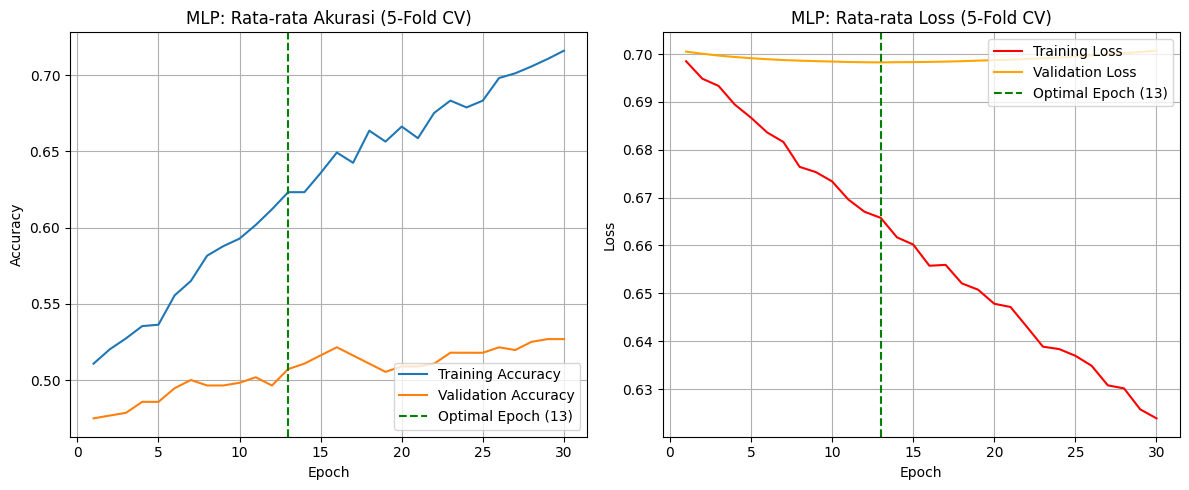

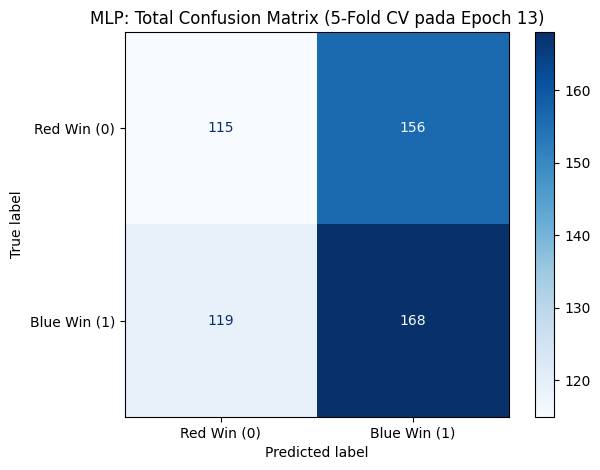

In [21]:
# ==============================================================================
# 5. VISUALISASI KURVA PEMBELAJARAN DAN CONFUSION MATRIX
# ==============================================================================
epochs_range = range(1, MAX_EPOCHS + 1)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, avg_acc, label='Training Accuracy')
plt.plot(epochs_range, avg_val_acc, label='Validation Accuracy')
plt.axvline(final_epoch_mlp, color='green', linestyle='--', label=f'Optimal Epoch ({final_epoch_mlp})')
plt.title('MLP: Rata-rata Akurasi (5-Fold CV)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, avg_loss, label='Training Loss', color='red')
plt.plot(epochs_range, avg_val_loss, label='Validation Loss', color='orange')
plt.axvline(final_epoch_mlp, color='green', linestyle='--', label=f'Optimal Epoch ({final_epoch_mlp})')
plt.title('MLP: Rata-rata Loss (5-Fold CV)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)
plt.tight_layout()
plt.show()

disp = ConfusionMatrixDisplay(confusion_matrix=total_cm, display_labels=['Red Win (0)', 'Blue Win (1)'])
disp.plot(cmap='Blues', values_format='g')
plt.title(f'MLP: Total Confusion Matrix (5-Fold CV pada Epoch {final_epoch_mlp})')
plt.tight_layout()
plt.show()

In [23]:
# ==============================================================================
# 6. FINAL TRAINING MLP PADA 100% DATASET UNTUK DEPLOYMENT
# ==============================================================================
print("\n" + "=" * 70)
print("FINAL TRAINING MLP (100% DATASET)")
print("=" * 70)
print(f"Jumlah Data : {len(X_mlp)} pertandingan | Epoch Final: {final_epoch_mlp} | Batch Size: {BATCH_SIZE}")

clear_session()
tf.keras.utils.set_random_seed(SEED)

final_mlp_model = build_mlp_model()
final_history_mlp = final_mlp_model.fit(
    X_mlp, y_mlp,
    epochs=final_epoch_mlp,
    batch_size=BATCH_SIZE,
    verbose=1
)

mlp_save_path = f'{MODEL_DIR}/mlp_match_prediction_model.keras'
final_mlp_model.save(mlp_save_path)
print(f"\nModel MLP final berhasil disimpan di: '{mlp_save_path}'")
print("Catatan: Metrik training pada model final tidak digunakan sebagai estimasi generalisasi.")


FINAL TRAINING MLP (100% DATASET)
Jumlah Data : 558 pertandingan | Epoch Final: 13 | Batch Size: 32
Epoch 1/13
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5161 - loss: 0.6955
Epoch 2/13
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5161 - loss: 0.6925
Epoch 3/13
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5215 - loss: 0.6879
Epoch 4/13
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5520 - loss: 0.6821
Epoch 5/13
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5663 - loss: 0.6807
Epoch 6/13
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5466 - loss: 0.6835
Epoch 7/13
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5681 - loss: 0.6773
Epoch 8/13
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5806 - loss: 0.6739
Epoch 9/13
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6075 - loss: 0.6682
Epoch 10/13
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5986 - loss: 0.6692
Epoch 11/13
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accu